#### Assignment 1 — Task 1: Dataset & Algorithm Selection

---

**1. Dataset Description & Justification**

In [6]:
# ── Install / import libraries needed for dataset inspection ──────────────────
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [7]:
DATASET_PATH = './dataset'   # <-- update as needed

# ── Discover class folders ────────────────────────────────────────────────────
train_dir = os.path.join(DATASET_PATH, 'Training Data', 'Training Data')
test_dir  = os.path.join(DATASET_PATH, 'Testing Data',  'Testing Data')
val_dir   = os.path.join(DATASET_PATH, 'Validation Data', 'Validation Data')

classes = sorted(os.listdir(train_dir))
print(f"Number of animal classes  : {len(classes)}")
print(f"Classes detected          : {classes}")

Number of animal classes  : 15
Classes detected          : ['Beetle', 'Butterfly', 'Cat', 'Cow', 'Dog', 'Elephant', 'Gorilla', 'Hippo', 'Lizard', 'Monkey', 'Mouse', 'Panda', 'Spider', 'Tiger', 'Zebra']


In [8]:
# ── Count images per class (train / val / test) ───────────────────────────────
def count_images(root, classes):
    counts = {}
    for cls in classes:
        p = os.path.join(root, cls)
        if os.path.isdir(p):
            counts[cls] = len([
                f for f in os.listdir(p)
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
            ])
        else:
            counts[cls] = 0
    return counts

train_counts = count_images(train_dir, classes)
val_counts   = count_images(val_dir,   classes)
test_counts  = count_images(test_dir,  classes)

summary_df = pd.DataFrame({
    'Class'  : classes,
    'Train'  : [train_counts[c] for c in classes],
    'Val'    : [val_counts[c]   for c in classes],
    'Test'   : [test_counts[c]  for c in classes],
})
summary_df['Total'] = summary_df['Train'] + summary_df['Val'] + summary_df['Test']

print(summary_df.to_string(index=False))
print(f"\nTotal images in dataset : {summary_df['Total'].sum()}")

    Class  Train  Val  Test  Total
   Beetle   2000  200   100   2300
Butterfly   2000  200   100   2300
      Cat   2000  100   394   2494
      Cow   2000  100   177   2277
      Dog   2000  100    88   2188
 Elephant   2000  100   306   2406
  Gorilla   2000  100    30   2130
    Hippo   2000  100    57   2157
   Lizard   2000  200   100   2300
   Monkey   2000  100   184   2284
    Mouse   2000  200   100   2300
    Panda   2000  100   237   2337
   Spider   2000  200   100   2300
    Tiger   2000  100   164   2264
    Zebra   2000  100   270   2370

Total images in dataset : 34407


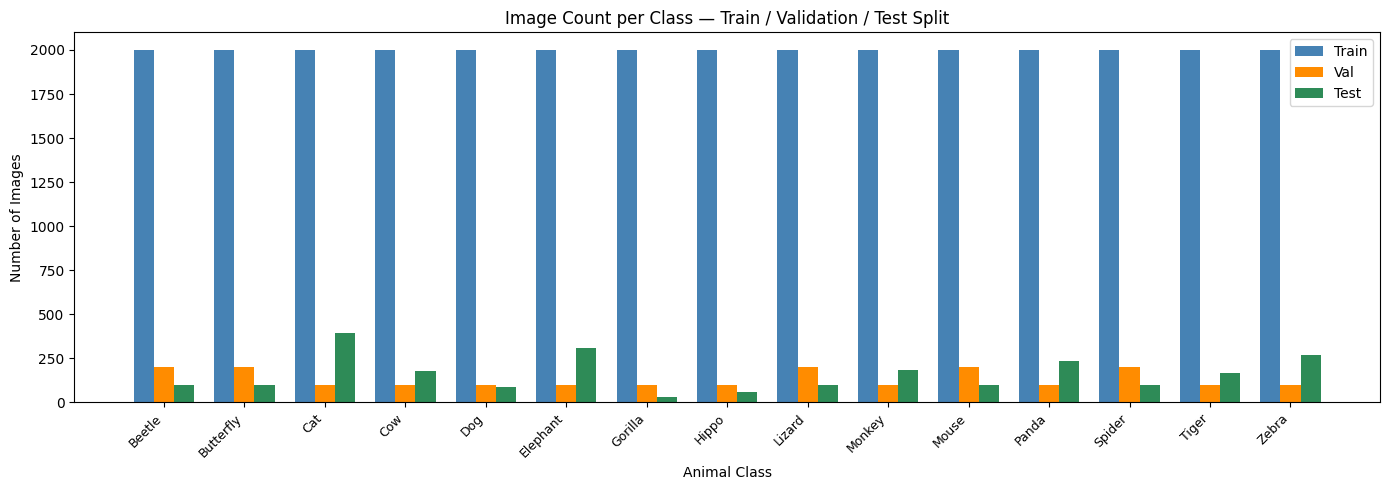

Figure saved as class_distribution.png


In [9]:
# ── Visualise dataset size summary ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(classes))
w = 0.25
ax.bar(x - w, summary_df['Train'], w, label='Train',  color='steelblue')
ax.bar(x,     summary_df['Val'],   w, label='Val',    color='darkorange')
ax.bar(x + w, summary_df['Test'],  w, label='Test',   color='seagreen')
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=45, ha='right', fontsize=9)
ax.set_xlabel('Animal Class')
ax.set_ylabel('Number of Images')
ax.set_title('Image Count per Class — Train / Validation / Test Split')
ax.legend()
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()
print("Figure saved as class_distribution.png")

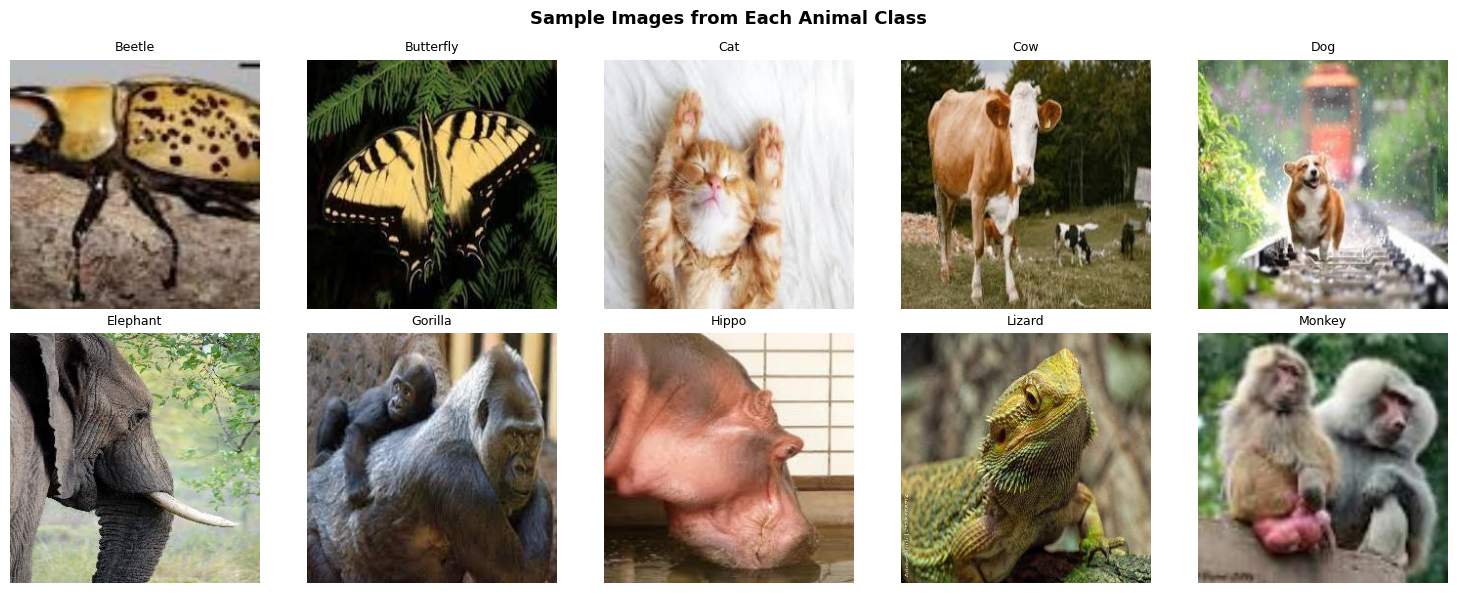

In [10]:
# ── Sample image previews per class ──────────────────────────────────────────
n_show = min(len(classes), 10)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, cls in enumerate(classes[:n_show]):
    cls_folder = os.path.join(train_dir, cls)
    imgs = [f for f in os.listdir(cls_folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if imgs:
        img_path = os.path.join(cls_folder, imgs[0])
        img = Image.open(img_path).convert('RGB')
        axes[i].imshow(img)
        axes[i].set_title(cls.capitalize(), fontsize=9)
        axes[i].axis('off')

for j in range(n_show, len(axes)):
    axes[j].axis('off')

plt.suptitle('Sample Images from Each Animal Class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150)
plt.show()

---
**2. Selected Deep Learning Algorithms**

*Algorithm 1: Custom Convolutional Neural Network (CNN)*

*Algorithm 2: Transfer Learning with ResNet50 (Fine-tuned)*

In [11]:
# ── Architecture Visualisation (text-based schematic) ─────────────────────────
import sys
import subprocess

try:
    import tensorflow as tf
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "tensorflow"])
    import tensorflow as tf
from tensorflow.keras import layers, models

N_CLASSES = len(classes)   # determined from dataset scan above
IMG_SIZE  = (224, 224)

def build_custom_cnn(n_classes, img_size=(224, 224, 3)):
    """Custom CNN — Algorithm 1."""
    inputs = tf.keras.Input(shape=img_size)
    x = inputs
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, (3,3), padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(filters, (3,3), padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(2, 2)(x)
        x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)
    return models.Model(inputs, outputs, name='Custom_CNN')

def build_resnet_transfer(n_classes, img_size=(224, 224, 3)):
    """ResNet50 Transfer Learning — Algorithm 2."""
    base = tf.keras.applications.ResNet50(
        include_top=False, weights='imagenet', input_shape=img_size)
    base.trainable = False   # Frozen initially
    inputs  = tf.keras.Input(shape=img_size)
    x       = base(inputs, training=False)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.Dense(256, activation='relu')(x)
    x       = layers.Dropout(0.4)(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)
    return models.Model(inputs, outputs, name='ResNet50_Transfer')

cnn_model     = build_custom_cnn(N_CLASSES)
resnet_model  = build_resnet_transfer(N_CLASSES)

print("=" * 55)
print("  ALGORITHM 1 — Custom CNN")
print("=" * 55)
cnn_model.summary()

print("\n" + "=" * 55)
print("  ALGORITHM 2 — ResNet50 Transfer Learning")
print("=" * 55)
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
  ALGORITHM 1 — Custom CNN


Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,315,375 (5.02 MB)

 Trainable params: 1,313,455 (5.01 MB)

...

Model: "ResNet50_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,116,111 (92.00 MB)

 Trainable params: 528,399 (2.02 MB)

 Non-trainable params: 23,587,712 (89.98 MB)